In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
###converting excel to csv
from google.colab import files
import pandas as pd

uploaded = files.upload()
excel_file = list(uploaded.keys())[0]

df = pd.read_excel(excel_file)
csv_filename = excel_file.replace(".xlsx", ".csv")
df.to_csv(csv_filename, index=False)

files.download(csv_filename)

In [ ]:
# =========================
# BLOCK 0 — Upload (Colab)
# =========================
from google.colab import files
uploaded = files.upload()
print("Uploaded:", list(uploaded.keys()))

Saving metadata_full.csv to metadata_full.csv
Saving methylation_full.csv to methylation_full.csv
Saving methylation_sub.csv to methylation_sub.csv
Uploaded: ['metadata_full.csv', 'methylation_full.csv', 'methylation_sub.csv']


In [ ]:
# =========================
# BLOCK 1 — Imports + paths
# =========================
import pandas as pd
import numpy as np

FULL_X_PATH = "methylation_full.csv"
SUB_X_PATH  = "methylation_sub.csv"
META_PATH   = "metadata_full.csv"

ID_COL    = "submitter_id"
GROUP_COL = "tumor_stage"   # change if needed

# IMPORTANT: set delimiter explicitly
# If your header looks like: submitter_id,TSPY4,... use ","
# If it looks like: submitter_id<TAB>TSPY4... use "\t"
SEP = ","

In [ ]:
# ==========================================
# BLOCK 2 — Load FULL/SUB methylation + meta
# ==========================================
# Load FULL methylation
X_full = pd.read_csv(FULL_X_PATH, sep=SEP)
if ID_COL not in X_full.columns:
    raise ValueError(f"{FULL_X_PATH} must contain column '{ID_COL}'")

X_full[ID_COL] = X_full[ID_COL].astype(str)
X_full = X_full.set_index(ID_COL)

# Convert gene columns to numeric
X_full = X_full.apply(pd.to_numeric, errors="coerce")

# Load SUB methylation
X_sub = pd.read_csv(SUB_X_PATH, sep=SEP)
if ID_COL not in X_sub.columns:
    raise ValueError(f"{SUB_X_PATH} must contain column '{ID_COL}'")

X_sub[ID_COL] = X_sub[ID_COL].astype(str)
X_sub = X_sub.set_index(ID_COL)

X_sub = X_sub.apply(pd.to_numeric, errors="coerce")

# Load metadata
meta = pd.read_csv(META_PATH, sep=SEP)
if ID_COL not in meta.columns:
    raise ValueError(f"{META_PATH} must contain column '{ID_COL}'")
if GROUP_COL not in meta.columns:
    raise ValueError(f"{META_PATH} must contain group column '{GROUP_COL}'")

meta[ID_COL] = meta[ID_COL].astype(str)
meta = meta.set_index(ID_COL)

print("Loaded:")
print("  X_full:", X_full.shape)
print("  X_sub :", X_sub.shape)
print("  meta  :", meta.shape)

Loaded:
  X_full: (2546, 359)
  X_sub : (50, 359)
  meta  : (2546, 5)


In [ ]:
# =========================
# BLOCK 3 — Align samples
# =========================
# Keep only samples present in metadata
common_full = X_full.index.intersection(meta.index)
common_sub  = X_sub.index.intersection(meta.index)

X_full = X_full.loc[common_full].copy()
X_sub  = X_sub.loc[common_sub].copy()

meta_full = meta.loc[common_full].copy()
meta_sub  = meta.loc[common_sub].copy()

print("After sample alignment:")
print("  FULL shape:", X_full.shape)
print("  SUB shape :", X_sub.shape)
print("  Groups full:", meta_full[GROUP_COL].nunique())
print("  Groups sub :", meta_sub[GROUP_COL].nunique())

After sample alignment:
  FULL shape: (2546, 359)
  SUB shape : (50, 359)
  Groups full: 4
  Groups sub : 4


In [ ]:
# =========================================================
# BLOCK 4 — CRITICAL FIX: Align genes + remove any NaN genes
# =========================================================
# 1) Use ONLY common genes
common_genes = X_full.columns.intersection(X_sub.columns)
X_full = X_full[common_genes].copy()
X_sub  = X_sub[common_genes].copy()

# 2) Enforce identical column order
X_sub = X_sub[X_full.columns].copy()

# 3) Remove genes with ANY missing values in either dataset
valid_genes = ~(X_full.isna().any(axis=0) | X_sub.isna().any(axis=0))
X_full = X_full.loc[:, valid_genes].copy()
X_sub  = X_sub.loc[:, valid_genes].copy()

print("After gene alignment + NaN filtering:")
print("  Genes FULL:", X_full.shape[1])
print("  Genes SUB :", X_sub.shape[1])
print("  Identical columns:", X_full.columns.equals(X_sub.columns))

After gene alignment + NaN filtering:
  Genes FULL: 359
  Genes SUB : 359
  Identical columns: True


In [ ]:
# ==========================================
# BLOCK 5 — Standardize (fit FULL, apply SUB)
# ==========================================
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler(with_mean=True, with_std=True)
Z_full = scaler.fit_transform(X_full.values)   # fit on FULL
Z_sub  = scaler.transform(X_sub.values)        # apply to SUB

In [ ]:
# ======================================
# BLOCK 6 — Total variance retained (%)
# ======================================
full_var = np.var(Z_full, axis=0, ddof=1).sum()
sub_var  = np.var(Z_sub,  axis=0, ddof=1).sum()
retained_pct = 100.0 * sub_var / full_var

print("Total variance (full):", round(full_var, 4))
print("Total variance (sub) :", round(sub_var, 4))
print("Variance retained (%):", round(retained_pct, 2))

Total variance (full): 359.1411
Total variance (sub) : 366.6692
Variance retained (%): 102.1


In [ ]:
# =========================
# BLOCK 7 — PC1 preservation
# =========================
from sklearn.decomposition import PCA

pc1_full = PCA().fit(Z_full).explained_variance_ratio_[0]
pc1_sub  = PCA().fit(Z_sub ).explained_variance_ratio_[0]

print("PC1 full:", round(pc1_full, 4))
print("PC1 sub :", round(pc1_sub, 4))
print("Difference (sub-full):", round(pc1_sub - pc1_full, 4))

PC1 full: 0.4519
PC1 sub : 0.4691
Difference (sub-full): 0.0173


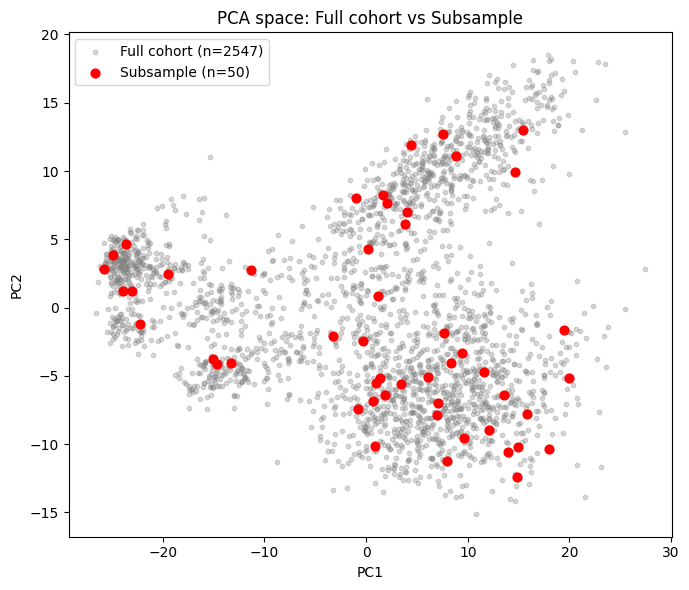

In [ ]:
# ==========================================
# BLOCK — PCA overlay: full vs subsample
# ==========================================

from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import numpy as np

# Fit PCA on FULL cohort
pca = PCA(n_components=2)
pca_full = pca.fit_transform(Z_full)

# Project subsample onto the SAME PCA space
pca_sub = pca.transform(Z_sub)

plt.figure(figsize=(7,6))

# Plot full cohort (light gray)
plt.scatter(
    pca_full[:,0],
    pca_full[:,1],
    s=10,
    alpha=0.3,
    color="gray",
    label="Full cohort (n=2546)"
)

# Plot subsample (red)
plt.scatter(
    pca_sub[:,0],
    pca_sub[:,1],
    s=40,
    color="red",
    label="Subsample (n=50)"
)

plt.xlabel("PC1")
plt.ylabel("PC2")

plt.title("PCA space: Full cohort vs Subsample")

plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
# ==========================================
# BLOCK 11 — Extract PC1 scores
# ==========================================

from sklearn.decomposition import PCA
import pandas as pd

pca = PCA()
pc_scores = pca.fit_transform(Z_full)

pc1 = pc_scores[:,0]

pc1_df = pd.DataFrame({
    "PC1": pc1
}, index=X_full.index)

# attach metadata
pc1_df = pc1_df.join(meta_full)

pc1_df.head()

,PC1,tumor_stage,age_at_diagnosis,race,gender,test_cancers
submitter_id,,,,,,
TCGA-DE-A4MB,5.417855,4,79.482192,3,0,2
TCGA-B6-A0RS,-21.053214,2,38.723288,3,0,1
TCGA-E8-A414,11.827340,3,45.901370,1,0,2
TCGA-AQ-A1H2,13.479523,3,84.816438,3,0,1
TCGA-QK-A6IG,15.676757,3,69.408219,3,1,5


In [ ]:
from scipy.stats import spearmanr

rho, p = spearmanr(pc1_df["PC1"], pc1_df["age_at_diagnosis"])

print("PC1 vs age_at_diagnosis")
print("Spearman rho:", rho)
print("p-value:", p)

PC1 vs age_at_diagnosis
Spearman rho: -0.003077540555143658
p-value: 0.8766554862401303


In [ ]:
from scipy.stats import f_oneway

def pc1_anova(var):

    groups = []

    for g in pc1_df[var].dropna().unique():
        groups.append(pc1_df.loc[pc1_df[var]==g,"PC1"])

    F,p = f_oneway(*groups)

    print(var)
    print("F:",round(F,4))
    print("p:",p)
    print()


for col in ["tumor_stage","race","gender","test_cancers"]:
    pc1_anova(col)

tumor_stage
F: 1.2866
p: 0.2772412775552231

race
F: 0.1947
p: 0.8231248897460468

gender
F: 0.265
p: 0.6067830201115675

test_cancers
F: 0.4957
p: 0.77967647583678



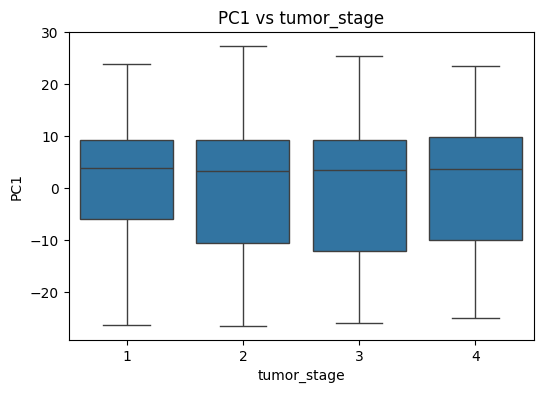

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(6,4))
sns.boxplot(x="tumor_stage",y="PC1",data=pc1_df)
plt.title("PC1 vs tumor_stage")
plt.show()

In [ ]:
# ==========================================
# BLOCK 7.5 — Cancer type F_ST (AMOVA-like)
# ==========================================
import numpy as np

def fst_amova_like(Z, labels):
    """
    AMOVA-like F_ST = SS_between / SS_total
    Z: standardized matrix (n_samples, n_features)
    labels: group labels (n_samples,)
    """
    Z = np.asarray(Z)
    labels = np.asarray(labels).astype(str)

    mu = Z.mean(axis=0, keepdims=True)

    ss_total = np.sum((Z - mu) ** 2)
    if ss_total <= 0:
        return np.nan

    ss_between = 0.0
    for c in np.unique(labels):
        idx = labels == c
        n_c = idx.sum()
        if n_c <= 0:
            continue
        mu_c = Z[idx].mean(axis=0, keepdims=True)
        ss_between += n_c * np.sum((mu_c - mu) ** 2)

    return float(ss_between / ss_total)

fst_full = fst_amova_like(Z_full, meta_full[GROUP_COL].values)
fst_sub  = fst_amova_like(Z_sub,  meta_sub[GROUP_COL].values)

print("Cancer type F_ST (full):", round(fst_full, 4))
print("Cancer type F_ST (sub) :", round(fst_sub, 4))
print("F_ST retained (%):", round(100.0 * fst_sub / fst_full, 2))

Cancer type F_ST (full): 0.0013
Cancer type F_ST (sub) : 0.0332
F_ST retained (%): 2594.63


In [ ]:
# =========================================
# BLOCK 8 — Cancer-type distribution table
# =========================================
dist = pd.DataFrame({
    "full_n": meta_full[GROUP_COL].astype(str).value_counts(),
    "sub_n":  meta_sub[GROUP_COL].astype(str).value_counts()
}).fillna(0).astype(int)

dist["full_%"] = (100 * dist["full_n"] / dist["full_n"].sum()).round(2)
dist["sub_%"]  = (100 * dist["sub_n"]  / dist["sub_n"].sum()).round(2)
dist["Δ%"]     = (dist["sub_%"] - dist["full_%"]).round(2)

display(dist.sort_values("full_n", ascending=False))
# Sort before saving (same order as displayed)
dist_sorted = dist.sort_values("full_n", ascending=False)

# Save to CSV
file_name = "cancer_type_distribution_full_vs_sub.csv"
dist_sorted.to_csv(file_name)

print("Saved as:", file_name)

# Download file
from google.colab import files
files.download(file_name)

,full_n,sub_n,full_%,sub_%,Δ%
tumor_stage,,,,,
2,777,15,30.52,30.0,-0.52
1,671,17,26.36,34.0,7.64
3,604,11,23.72,22.0,-1.72
4,494,7,19.40,14.0,-5.40


Saved as: cancer_type_distribution_full_vs_sub.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

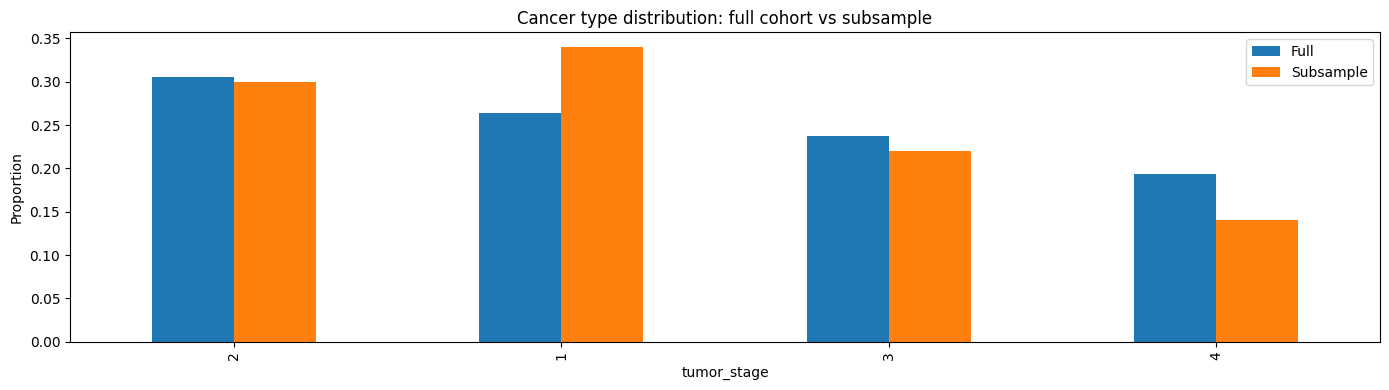

In [ ]:
# ==========================================
# BLOCK 8.5 — Cancer type distribution barplot
# ==========================================
import matplotlib.pyplot as plt

plot_df = dist.copy()

# Convert counts to proportions (0-1) for plotting (optional; % also fine)
plot_df["Full"] = plot_df["full_n"] / plot_df["full_n"].sum()
plot_df["Subsample"] = plot_df["sub_n"] / plot_df["sub_n"].sum()

plot_df = plot_df[["Full", "Subsample"]].sort_values("Full", ascending=False)

ax = plot_df.plot(kind="bar", figsize=(14,4))
ax.set_ylabel("Proportion")
ax.set_title("Cancer type distribution: full cohort vs subsample")
plt.tight_layout()
plt.show()

In [ ]:
# ==========================================
# BLOCK 9 — PERMANOVA (optional, structure)
# ==========================================
!pip -q install scikit-bio

from skbio.stats.distance import DistanceMatrix, permanova
from scipy.spatial.distance import pdist, squareform

def run_permanova(Z, groups, permutations=999):
    D = squareform(pdist(Z, metric="euclidean"))
    dm = DistanceMatrix(D)
    res = permanova(dm, grouping=groups.astype(str).values, permutations=permutations)
    return res.to_dict()

perm_full = run_permanova(Z_full, meta_full[GROUP_COL], permutations=999)
perm_sub  = run_permanova(Z_sub,  meta_sub[GROUP_COL],  permutations=999)

print("PERMANOVA full:", perm_full)
print("PERMANOVA sub :", perm_sub)

PERMANOVA full: {'method name': 'PERMANOVA', 'test statistic name': 'pseudo-F', 'sample size': 2546, 'number of groups': 4, 'test statistic': 1.0855339548849035, 'p-value': 0.349, 'number of permutations': 999}
PERMANOVA sub : {'method name': 'PERMANOVA', 'test statistic name': 'pseudo-F', 'sample size': 50, 'number of groups': 4, 'test statistic': 0.526511214758628, 'p-value': 0.957, 'number of permutations': 999}


In [ ]:
print(meta_full.columns)
print(meta_full[GROUP_COL].nunique())
print(meta_full[GROUP_COL].value_counts().head())

Index(['tumor_stage', 'age_at_diagnosis', 'race', 'gender', 'test_cancers'], dtype='object')
4
tumor_stage
2    777
1    671
3    604
4    494
Name: count, dtype: int64


In [ ]:
for col in ["tumor_stage","age_at_diagnosis","race","gender","test_cancers"]:
    print(col, meta_full[col].nunique())

tumor_stage 4
age_at_diagnosis 2385
race 3
gender 2
test_cancers 6


In [ ]:
# ==========================================
# BLOCK 10 — PERMANOVA for all metadata variables
# ==========================================

print("Testing metadata variables as drivers of methylation variation\n")

for col in ["tumor_stage","age_at_diagnosis","race","gender","test_cancers"]:

    # skip columns with missing values
    groups = meta_full[col].dropna()

    # align samples
    idx = groups.index
    Z = Z_full[[X_full.index.get_loc(i) for i in idx]]

    res = run_permanova(Z, groups)

    print(f"{col}")
    print(" pseudo-F:", round(res["test statistic"],4))
    print(" p-value :", res["p-value"])
    print()

Testing metadata variables as drivers of methylation variation

tumor_stage
 pseudo-F: 1.0855
 p-value : 0.33

age_at_diagnosis
 pseudo-F: 0.9791
 p-value : 0.687

race
 pseudo-F: 0.4791
 p-value : 0.958

gender
 pseudo-F: 0.4676
 p-value : 0.838

test_cancers
 pseudo-F: 0.9264
 p-value : 0.548



In [ ]:
from skbio.stats.distance import DistanceMatrix, permanova
from scipy.spatial.distance import pdist, squareform
import numpy as np
import pandas as pd

def permanova_with_r2(Z, groups, permutations=999):
    # distance matrix
    D = squareform(pdist(Z, metric="euclidean"))
    dm = DistanceMatrix(D)

    # PERMANOVA test (pseudo-F + p-value)
    res = permanova(dm, grouping=groups.astype(str).values, permutations=permutations)

    # ---- compute R^2 (variance explained) from distances ----
    g = pd.Series(groups.astype(str).values)
    n = len(g)

    # total sum of squares from distances
    ss_total = (D**2).sum() / (2 * n)

    # within-group SS: sum over groups of (sum of squared distances within group)/(2*ng)
    ss_within = 0.0
    for level in g.unique():
        idx = np.where(g.values == level)[0]
        ng = len(idx)
        if ng <= 1:
            continue
        Dw = D[np.ix_(idx, idx)]
        ss_within += (Dw**2).sum() / (2 * ng)

    ss_between = ss_total - ss_within
    r2 = ss_between / ss_total if ss_total > 0 else np.nan

    return {
        "pseudo-F": float(res["test statistic"]),
        "p-value": float(res["p-value"]),
        "permutations": int(res["number of permutations"]),
        "n": int(res["sample size"]),
        "k_groups": int(res["number of groups"]),
        "R2": float(r2)
    }

perm_full = permanova_with_r2(Z_full, meta_full[GROUP_COL], permutations=999)
perm_sub  = permanova_with_r2(Z_sub,  meta_sub[GROUP_COL],  permutations=999)

print("PERMANOVA full:", perm_full)
print("PERMANOVA sub :", perm_sub)

PERMANOVA full: {'pseudo-F': 1.0855339548849035, 'p-value': 0.332, 'permutations': 999, 'n': 2546, 'k_groups': 4, 'R2': 0.0012794788007907786}
PERMANOVA sub : {'pseudo-F': 0.526511214758628, 'p-value': 0.951, 'permutations': 999, 'n': 50, 'k_groups': 4, 'R2': 0.03319775380913011}


Random subsampling R2 mean: 0.0584
Random subsampling R2 std : 0.0199
Observed SUB R2          : 0.0332
Observed percentile       : 6.0 %


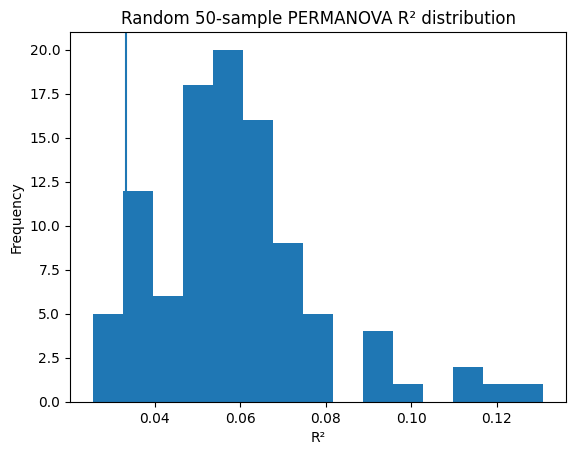

In [ ]:
import numpy as np
import pandas as pd
from scipy.spatial.distance import pdist, squareform
from skbio.stats.distance import DistanceMatrix
from skbio.stats.distance import permanova
import matplotlib.pyplot as plt

# -----------------------------
# Helper: compute PERMANOVA R2
# -----------------------------
def permanova_r2(Z, groups, permutations=0):
    """
    Computes PERMANOVA R2 (variance explained).
    Permutations set to 0 for speed in repeated subsampling.
    """
    D = squareform(pdist(Z, metric="euclidean"))
    dm = DistanceMatrix(D)

    # Run permanova (no permutations needed for R2)
    res = permanova(dm, grouping=groups.astype(str).values, permutations=permutations)

    g = pd.Series(groups.astype(str).values)
    n = len(g)

    ss_total = (D**2).sum() / (2 * n)

    ss_within = 0.0
    for level in g.unique():
        idx = np.where(g.values == level)[0]
        ng = len(idx)
        if ng <= 1:
            continue
        Dw = D[np.ix_(idx, idx)]
        ss_within += (Dw**2).sum() / (2 * ng)

    ss_between = ss_total - ss_within
    r2 = ss_between / ss_total if ss_total > 0 else np.nan

    return float(r2)

# -----------------------------------------
# Random subsampling from FULL
# -----------------------------------------

n_iterations = 100
subset_size = 50
random_r2 = []

np.random.seed(42)

for i in range(n_iterations):
    idx = np.random.choice(Z_full.shape[0], subset_size, replace=False)
    Z_sample = Z_full[idx]
    groups_sample = meta_full.iloc[idx][GROUP_COL]

    r2 = permanova_r2(Z_sample, groups_sample, permutations=0)
    random_r2.append(r2)

random_r2 = np.array(random_r2)

# -----------------------------------------
# Compare with your observed SUB R2
# -----------------------------------------

observed_sub_r2 = perm_sub["R2"]

mean_r2 = random_r2.mean()
std_r2 = random_r2.std()
percentile = (random_r2 < observed_sub_r2).mean() * 100

print("Random subsampling R2 mean:", round(mean_r2, 4))
print("Random subsampling R2 std :", round(std_r2, 4))
print("Observed SUB R2          :", round(observed_sub_r2, 4))
print("Observed percentile       :", round(percentile, 1), "%")

# -----------------------------------------
# Plot distribution
# -----------------------------------------

plt.figure()
plt.hist(random_r2, bins=15)
plt.axvline(observed_sub_r2)
plt.title("Random 50-sample PERMANOVA R² distribution")
plt.xlabel("R²")
plt.ylabel("Frequency")
plt.show()

In [ ]:
print(meta.columns)

Index(['tumor_stage', 'age_at_diagnosis', 'race', 'gender', 'test_cancers'], dtype='object')


In [ ]:
meta_full["test_cancers"].unique()

array([2, 1, 5, 4, 6, 3])

In [ ]:
###TRung to resolve kristel questions for npj oncology journal

In [ ]:
# =========================
# MAP Sample_1...Sample_50 to TCGA Submitter IDs
# =========================
import pandas as pd

# -------------------------
# STEP 1 — Load methylation_sub.csv to get submitter IDs in order
# -------------------------
methyl_sub = pd.read_csv("methylation_sub.csv")

# Extract submitter IDs in sequential order (as they appear in the file)
submitter_ids = methyl_sub["submitter_id"].tolist()

print("Total submitter IDs found:", len(submitter_ids))
print("First 5 IDs:", submitter_ids[:5])

# -------------------------
# STEP 2 — Load LIONESS output
# -------------------------
lioness = pd.read_csv("labeled_lioness_data.csv")

# Check current columns
print("\nLIONESS columns (first 5):", lioness.columns[:5].tolist())
print("LIONESS shape:", lioness.shape)

# -------------------------
# STEP 3 — Create Sample → Submitter ID mapping
# -------------------------
# Sample_1 → first ID, Sample_2 → second ID, etc.
sample_cols = [col for col in lioness.columns if col.startswith("Sample_")]

print("\nNumber of Sample columns found:", len(sample_cols))

# Create mapping dictionary
mapping = {f"Sample_{i+1}": submitter_ids[i] for i in range(len(submitter_ids))}

print("\nMapping (first 5):")
for k, v in list(mapping.items())[:5]:
    print(f"  {k} → {v}")

# -------------------------
# STEP 4 — Rename columns in LIONESS output
# -------------------------
lioness_labeled = lioness.rename(columns=mapping)

# Verify
print("\nLIONESS columns after renaming (first 5):")
print(lioness_labeled.columns[:7].tolist())  # first 2 are tf, gene

# -------------------------
# STEP 5 — Save labeled LIONESS file
# -------------------------
lioness_labeled.to_csv("lioness_labeled_with_ids.csv", index=False)
print("\nSaved: lioness_labeled_with_ids.csv")

# -------------------------
# STEP 6 — Quick verification table
# -------------------------
mapping_df = pd.DataFrame({
    "Sample_Name": list(mapping.keys()),
    "Submitter_ID": list(mapping.values())
})
print("\nFull mapping table:")
print(mapping_df.to_string())

# Save mapping table too
mapping_df.to_csv("sample_to_submitter_mapping.csv", index=False)
print("\nSaved: sample_to_submitter_mapping.csv")

Total submitter IDs found: 50
First 5 IDs: ['TCGA-FY-A40N', 'TCGA-DK-AA74', 'TCGA-AK-3431', 'TCGA-BJ-A191', 'TCGA-EU-5906']

LIONESS columns (first 5): ['tf', 'gene', 'Sample_1', 'Sample_2', 'Sample_3']
LIONESS shape: (128881, 52)

Number of Sample columns found: 50

Mapping (first 5):
  Sample_1 → TCGA-FY-A40N
  Sample_2 → TCGA-DK-AA74
  Sample_3 → TCGA-AK-3431
  Sample_4 → TCGA-BJ-A191
  Sample_5 → TCGA-EU-5906

LIONESS columns after renaming (first 5):
['tf', 'gene', 'TCGA-FY-A40N', 'TCGA-DK-AA74', 'TCGA-AK-3431', 'TCGA-BJ-A191', 'TCGA-EU-5906']

Saved: lioness_labeled_with_ids.csv

Full mapping table:
   Sample_Name  Submitter_ID
0     Sample_1  TCGA-FY-A40N
1     Sample_2  TCGA-DK-AA74
2     Sample_3  TCGA-AK-3431
3     Sample_4  TCGA-BJ-A191
4     Sample_5  TCGA-EU-5906
5     Sample_6  TCGA-E7-A3X6
6     Sample_7  TCGA-EW-A1IZ
7     Sample_8  TCGA-BP-5169
8     Sample_9  TCGA-NK-A5D1
9    Sample_10  TCGA-B0-5094
10   Sample_11  TCGA-CN-4722
11   Sample_12  TCGA-CF-A47X
12   Sampl

In [ ]:
# =========================
# LINK 50 SAMPLES TO CLINICAL METADATA
# =========================
import pandas as pd

# -------------------------
# STEP 1 — Load your clinical metadata
# -------------------------
meta = pd.read_csv("metadata_full.csv")  # adjust filename if different
meta["submitter_id"] = meta["submitter_id"].astype(str)
meta = meta.set_index("submitter_id")

print("Metadata shape:", meta.shape)
print("Metadata columns:", meta.columns.tolist())

# -------------------------
# STEP 2 — Extract metadata for your 50 samples
# -------------------------
submitter_ids = [
    'TCGA-FY-A40N', 'TCGA-DK-AA74', 'TCGA-AK-3431', 'TCGA-BJ-A191',
    'TCGA-EU-5906', 'TCGA-E7-A3X6', 'TCGA-EW-A1IZ', 'TCGA-BP-5169',
    'TCGA-NK-A5D1', 'TCGA-B0-5094', 'TCGA-CN-4722', 'TCGA-CF-A47X',
    'TCGA-56-8304', 'TCGA-QK-A652', 'TCGA-D8-A27N', 'TCGA-4Z-AA7Y',
    'TCGA-LD-A7W6', 'TCGA-BP-5182', 'TCGA-C8-A27A', 'TCGA-FD-A6TH',
    'TCGA-CN-6994', 'TCGA-39-5022', 'TCGA-BP-5173', 'TCGA-56-8626',
    'TCGA-EL-A4KH', 'TCGA-CF-A3MH', 'TCGA-D8-A27L', 'TCGA-AR-A252',
    'TCGA-E9-A1RA', 'TCGA-GD-A6C6', 'TCGA-94-8035', 'TCGA-EL-A4KG',
    'TCGA-BH-A0W4', 'TCGA-CU-A0YN', 'TCGA-98-A53J', 'TCGA-BJ-A2N8',
    'TCGA-P3-A5Q6', 'TCGA-77-6845', 'TCGA-34-5234', 'TCGA-CV-6933',
    'TCGA-CN-6988', 'TCGA-OL-A66I', 'TCGA-E9-A2JS', 'TCGA-CV-7428',
    'TCGA-BH-A0C3', 'TCGA-CV-5977', 'TCGA-ET-A2N5', 'TCGA-CN-5370',
    'TCGA-H2-A26U', 'TCGA-EL-A4K9'
]

# Check overlap
found = [id for id in submitter_ids if id in meta.index]
missing = [id for id in submitter_ids if id not in meta.index]

print(f"\nFound in metadata: {len(found)}/50")
print(f"Missing from metadata: {len(missing)}")
if missing:
    print("Missing IDs:", missing)

# -------------------------
# STEP 3 — Extract and save metadata for 50 samples
# -------------------------
meta_sub = meta.loc[found].copy()

print("\nMetadata for 50 samples:")
print(meta_sub[["tumor_stage", "age_at_diagnosis", "race", "gender", "test_cancers"]])

print("\nTumor stage distribution:")
print(meta_sub["tumor_stage"].value_counts())

print("\nGender distribution:")
print(meta_sub["gender"].value_counts())

print("\nCancer type distribution:")
print(meta_sub["test_cancers"].value_counts())

# Save
meta_sub.to_csv("metadata_sub_50.csv", index=True)
print("\nSaved: metadata_sub_50.csv")

Metadata shape: (2546, 5)
Metadata columns: ['tumor_stage', 'age_at_diagnosis', 'race', 'gender', 'test_cancers']

Found in metadata: 50/50
Missing from metadata: 0

Metadata for 50 samples:
              tumor_stage  age_at_diagnosis  race  gender  test_cancers
submitter_id                                                           
TCGA-FY-A40N            1         55.671233     3       0             2
TCGA-DK-AA74            3         75.972603     3       1             3
TCGA-AK-3431            2         62.608219     3       0             6
TCGA-BJ-A191            1         49.758904     3       0             2
TCGA-EU-5906            1         55.468493     3       1             6
TCGA-E7-A3X6            2         70.093151     3       1             3
TCGA-EW-A1IZ            3         53.989041     3       0             1
TCGA-BP-5169            1         70.178082     3       1             6
TCGA-NK-A5D1            2         57.284932     3       1             4
TCGA-B0-5094     

Dataset shape    : (50, 10)

Cluster distribution:
cluster
0      2
1      3
2      4
3      5
4      8
5     18
6      2
7      1
8      3
9      1
10     3
Name: count, dtype: int64

ANALYSIS 1 — TUMOR STAGE vs CLUSTER (Kruskal-Wallis)

Kruskal-Wallis H statistic : 6.3880
p-value                    : 7.8168e-01
Interpretation             : Not significant (p >= 0.05)
Note: Report median stage per cluster as descriptive evidence.

Median tumor stage per cluster:
cluster
0     1.5
1     2.0
2     1.5
3     3.0
4     2.0
5     2.0
6     2.5
7     1.0
8     2.0
9     4.0
10    2.0
Saved: median_stage_per_cluster.csv


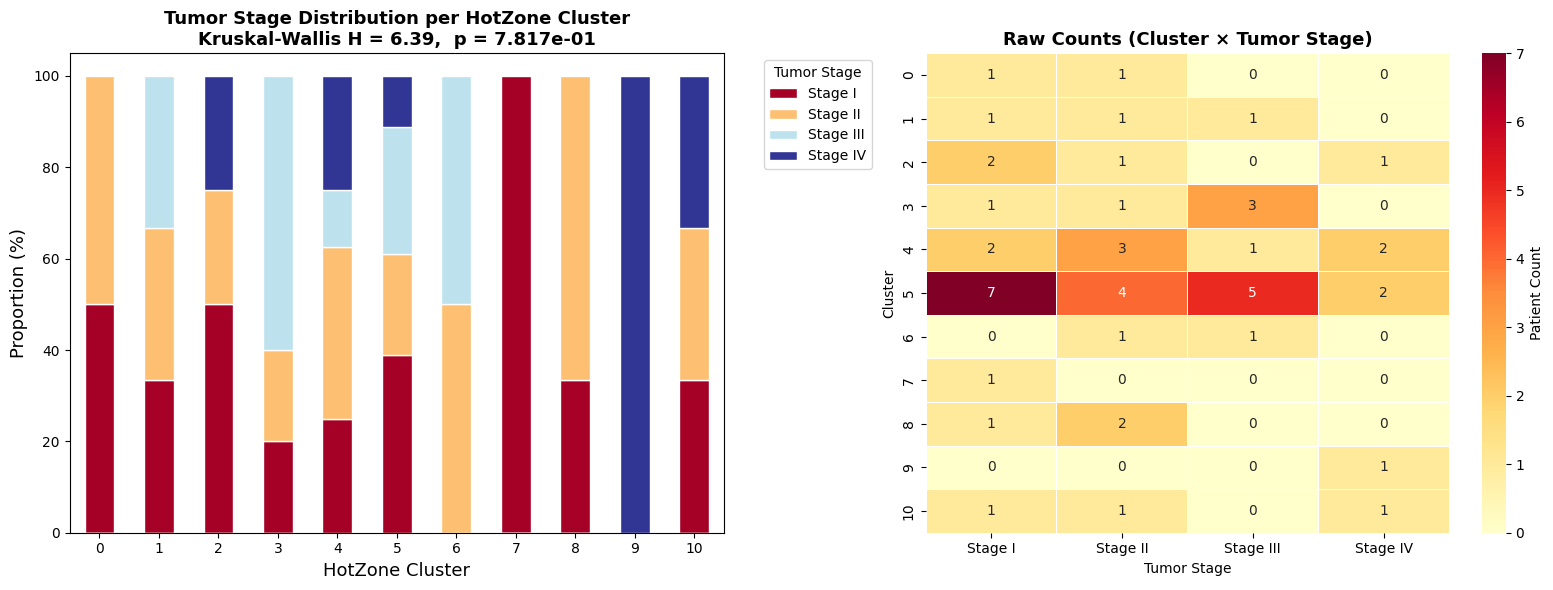

Saved: tumor_stage_per_cluster.png

ANALYSIS 2 — CANCER TYPE vs CLUSTER (Chi-square)

Raw counts (Cluster × Cancer Type):
cancer_label  Type1  Type2  Type3  Type4  Type5  Type6
cluster                                               
0                 1      1      0      0      0      0
1                 0      0      0      2      1      0
2                 1      0      0      1      1      1
3                 1      1      1      1      1      0
4                 0      2      0      2      2      2
5                 5      3      4      1      3      2
6                 1      1      0      0      0      0
7                 0      0      0      0      0      1
8                 1      0      2      0      0      0
9                 0      0      1      0      0      0
10                1      0      0      1      1      0

Chi-square statistic : 45.9691
Degrees of freedom   : 50
p-value              : 6.3581e-01
Interpretation       : Not significant (p >= 0.05)

Expected count < 5 

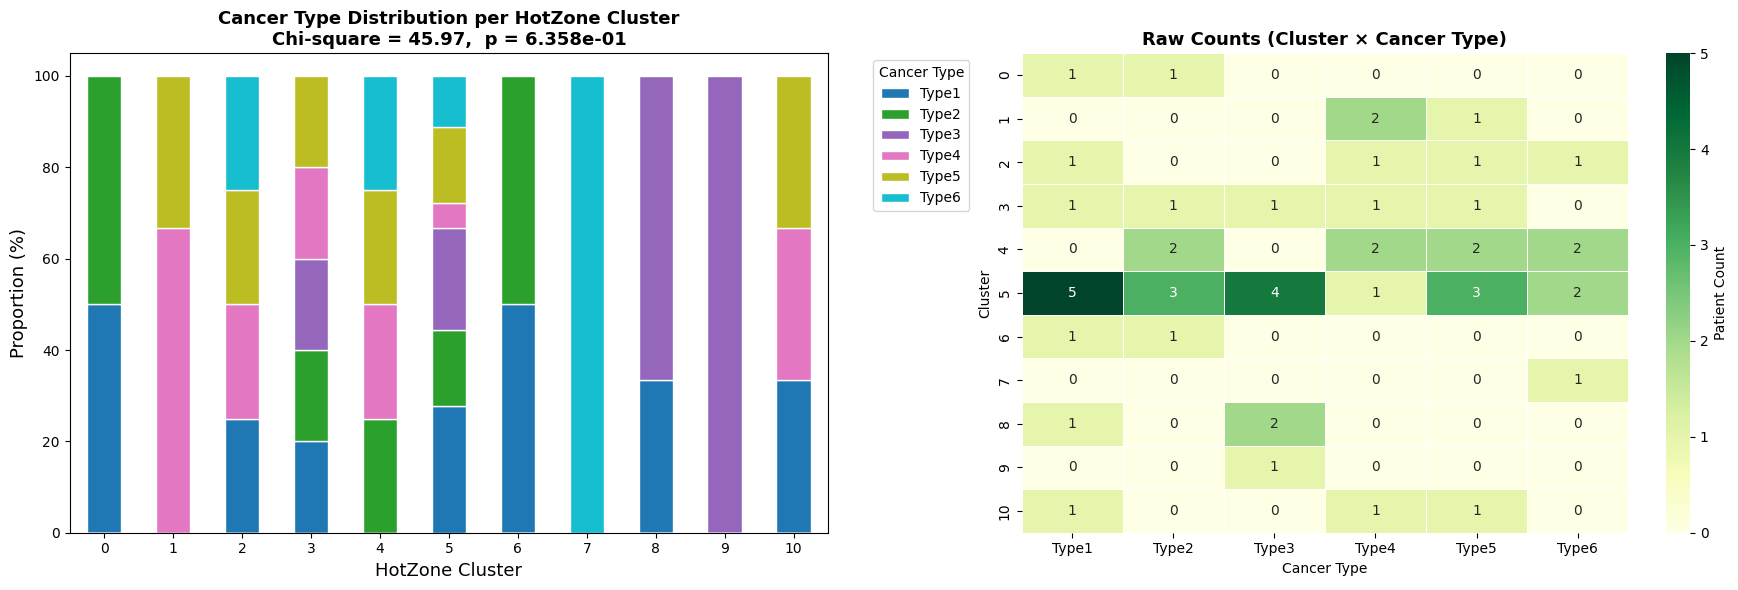

Saved: cancer_type_per_cluster.png

ANALYSIS 3 — GENDER vs CLUSTER (Fisher + BH-FDR) [Supplementary]

Raw counts (Cluster × Gender):
gender_label  Female  Male
cluster                   
0                  2     0
1                  1     2
2                  1     3
3                  2     3
4                  4     4
5                  8    10
6                  2     0
7                  0     1
8                  1     2
9                  0     1
10                 1     2

Proportions per cluster (%):
gender_label  Female   Male
cluster                    
0              100.0    0.0
1               33.3   66.7
2               25.0   75.0
3               40.0   60.0
4               50.0   50.0
5               44.4   55.6
6              100.0    0.0
7                0.0  100.0
8               33.3   66.7
9                0.0  100.0
10              33.3   66.7

Global chi-square p-value : 6.4693e-01
(Overview only — pairwise Fisher used for cluster-level inference)
Saved: fisher_g

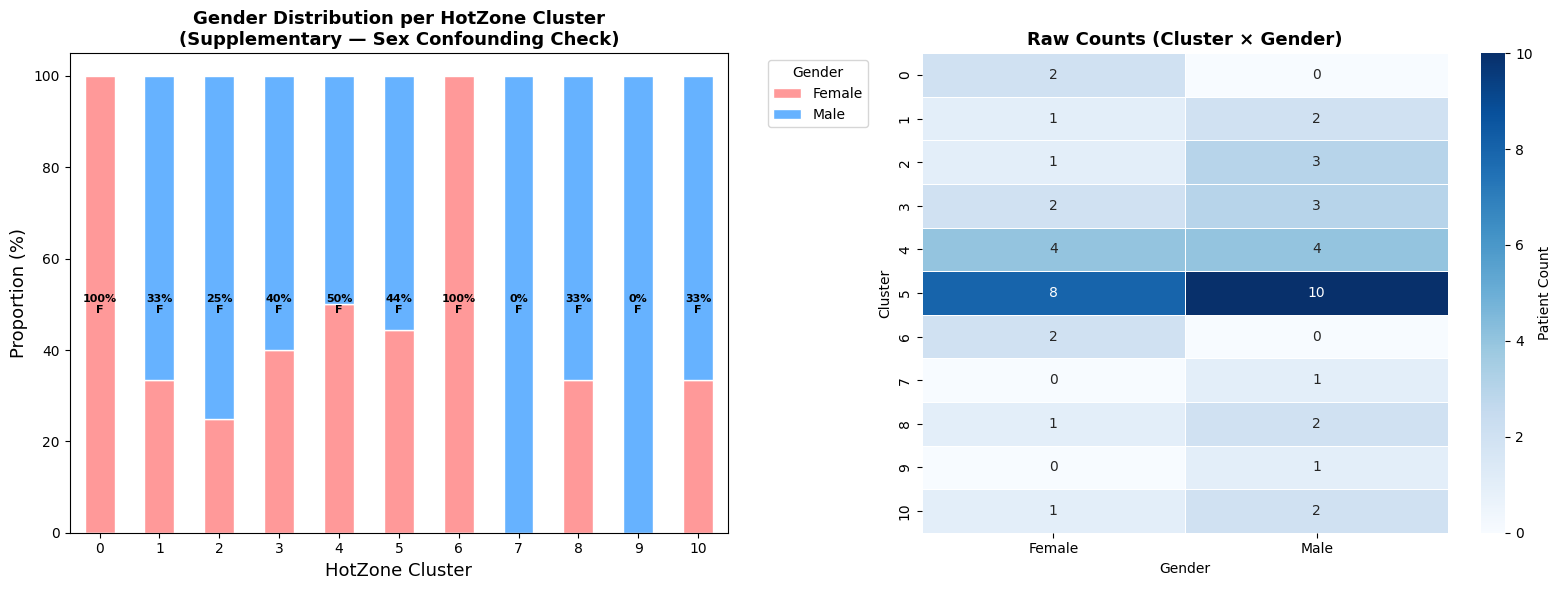

Saved: gender_per_cluster.png

SUMMARY OF ALL STATISTICAL TESTS
              Analysis                  Test    Statistic    p_value Significant                            Role
Tumor Stage vs Cluster        Kruskal-Wallis   H = 6.3880 7.8168e-01          No       Primary clinical endpoint
Cancer Type vs Cluster            Chi-square X2 = 45.9691 6.3581e-01          No           Biological validation
     Gender vs Cluster Fisher exact + BH-FDR  X2 = 7.8148 6.4693e-01          No Supplementary confounding check

Saved: statistical_summary_final.csv


In [7]:
# =============================================================
# BLOCK 3 — HotZone Cluster vs Clinical Endpoints
# Three analyses:
#   1. Tumor Stage vs Cluster     — Kruskal-Wallis (primary endpoint)
#   2. Cancer Type vs Cluster     — Chi-square (biological validation)
#   3. Gender vs Cluster          — Fisher + BH-FDR (supplementary)
# =============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency, kruskal, fisher_exact
from statsmodels.stats.multitest import multipletests
from itertools import combinations

# -------------------------
# LOAD & PREPARE DATA
# -------------------------
cluster_meta = pd.read_csv("hotzone_clusters_with_metadata.csv")

# Readable labels
cluster_meta["gender_label"] = cluster_meta["gender"].map({0: "Female", 1: "Male"})
cluster_meta["stage_label"]  = cluster_meta["tumor_stage"].map({
    1: "Stage I", 2: "Stage II", 3: "Stage III", 4: "Stage IV"
})
cancer_map = {1: "Type1", 2: "Type2", 3: "Type3",
              4: "Type4", 5: "Type5", 6: "Type6"}
cluster_meta["cancer_label"] = cluster_meta["test_cancers"].map(cancer_map)

print("Dataset shape    :", cluster_meta.shape)
print("\nCluster distribution:")
print(cluster_meta["cluster"].value_counts().sort_index())


# ============================================================
# ANALYSIS 1 — TUMOR STAGE vs CLUSTER (Kruskal-Wallis)
# Stage is ordinal (I < II < III < IV)
# Kruskal-Wallis is the correct non-parametric test for
# comparing an ordinal variable across multiple groups
# ============================================================
print("\n" + "="*60)
print("ANALYSIS 1 — TUMOR STAGE vs CLUSTER (Kruskal-Wallis)")
print("="*60)

# Drop missing stage values
stage_data = cluster_meta.dropna(subset=["tumor_stage"]).copy()

# Build one array of stage values per cluster
clusters_sorted = sorted(stage_data["cluster"].unique())
groups_stage = [
    stage_data.loc[stage_data["cluster"] == c, "tumor_stage"].values
    for c in clusters_sorted
]

# Global Kruskal-Wallis test
stat_kw, p_kw = kruskal(*groups_stage)

print(f"\nKruskal-Wallis H statistic : {stat_kw:.4f}")
print(f"p-value                    : {p_kw:.4e}")

if p_kw < 0.001:
    print("Interpretation             : *** Highly significant (p < 0.001)")
elif p_kw < 0.01:
    print("Interpretation             : ** Significant (p < 0.01)")
elif p_kw < 0.05:
    print("Interpretation             : * Significant (p < 0.05)")
else:
    print("Interpretation             : Not significant (p >= 0.05)")
    print("Note: Report median stage per cluster as descriptive evidence.")

# Median tumor stage per cluster — effect size measure
median_stage = stage_data.groupby("cluster")["tumor_stage"].median().round(1)
print("\nMedian tumor stage per cluster:")
print(median_stage.to_string())
median_stage.to_csv("median_stage_per_cluster.csv", header=["Median_Stage"])
print("Saved: median_stage_per_cluster.csv")

# Contingency table for plotting
stage_counts = pd.crosstab(stage_data["cluster"], stage_data["stage_label"])
stage_pct    = stage_counts.div(stage_counts.sum(axis=1), axis=0) * 100

# --- Figure: stacked bar + raw count heatmap ---
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

stage_pct.plot(
    kind="bar", stacked=True, colormap="RdYlBu",
    ax=axes[0], edgecolor="white"
)
axes[0].set_xlabel("HotZone Cluster", fontsize=13)
axes[0].set_ylabel("Proportion (%)", fontsize=13)
axes[0].set_title(
    f"Tumor Stage Distribution per HotZone Cluster\n"
    f"Kruskal-Wallis H = {stat_kw:.2f},  p = {p_kw:.3e}",
    fontsize=13, fontweight="bold"
)
axes[0].legend(title="Tumor Stage", bbox_to_anchor=(1.05, 1), loc="upper left")
axes[0].tick_params(axis="x", rotation=0)

sns.heatmap(
    stage_counts, annot=True, fmt="d", cmap="YlOrRd",
    ax=axes[1], linewidths=0.5,
    cbar_kws={"label": "Patient Count"}
)
axes[1].set_title(
    "Raw Counts (Cluster × Tumor Stage)",
    fontsize=13, fontweight="bold"
)
axes[1].set_xlabel("Tumor Stage")
axes[1].set_ylabel("Cluster")

plt.tight_layout()
plt.savefig("tumor_stage_per_cluster.png", dpi=300, bbox_inches="tight")
plt.show()
print("Saved: tumor_stage_per_cluster.png")


# ============================================================
# ANALYSIS 2 — CANCER TYPE vs CLUSTER (Chi-square)
# Cancer type is nominal (unordered categories)
# Chi-square is the correct test for nominal × nominal association
# ============================================================
print("\n" + "="*60)
print("ANALYSIS 2 — CANCER TYPE vs CLUSTER (Chi-square)")
print("="*60)

cancer_data   = cluster_meta.dropna(subset=["test_cancers"]).copy()
cancer_counts = pd.crosstab(cancer_data["cluster"], cancer_data["cancer_label"])
cancer_pct    = cancer_counts.div(cancer_counts.sum(axis=1), axis=0) * 100

print("\nRaw counts (Cluster × Cancer Type):")
print(cancer_counts)

# Chi-square test
chi2_stat, p_chi2, dof, expected = chi2_contingency(cancer_counts.values)

print(f"\nChi-square statistic : {chi2_stat:.4f}")
print(f"Degrees of freedom   : {dof}")
print(f"p-value              : {p_chi2:.4e}")

if p_chi2 < 0.001:
    print("Interpretation       : *** Highly significant (p < 0.001)")
elif p_chi2 < 0.01:
    print("Interpretation       : ** Significant (p < 0.01)")
elif p_chi2 < 0.05:
    print("Interpretation       : * Significant (p < 0.05)")
else:
    print("Interpretation       : Not significant (p >= 0.05)")

# Chi-square assumption check — report in paper if violated
cells_below5 = (expected < 5).sum()
pct_below5   = 100 * cells_below5 / expected.size
print(f"\nExpected count < 5 in {cells_below5}/{expected.size} "
      f"cells ({pct_below5:.1f}%)")
if pct_below5 > 20:
    print("NOTE: >20% of cells have expected count < 5.")
    print("Mention this in limitations — standard with small n.")

# --- Figure: stacked bar + raw count heatmap ---
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

cancer_pct.plot(
    kind="bar", stacked=True, colormap="tab10",
    ax=axes[0], edgecolor="white"
)
axes[0].set_xlabel("HotZone Cluster", fontsize=13)
axes[0].set_ylabel("Proportion (%)", fontsize=13)
axes[0].set_title(
    f"Cancer Type Distribution per HotZone Cluster\n"
    f"Chi-square = {chi2_stat:.2f},  p = {p_chi2:.3e}",
    fontsize=13, fontweight="bold"
)
axes[0].legend(title="Cancer Type", bbox_to_anchor=(1.05, 1), loc="upper left")
axes[0].tick_params(axis="x", rotation=0)

sns.heatmap(
    cancer_counts, annot=True, fmt="d", cmap="YlGn",
    ax=axes[1], linewidths=0.5,
    cbar_kws={"label": "Patient Count"}
)
axes[1].set_title(
    "Raw Counts (Cluster × Cancer Type)",
    fontsize=13, fontweight="bold"
)
axes[1].set_xlabel("Cancer Type")
axes[1].set_ylabel("Cluster")

plt.tight_layout()
plt.savefig("cancer_type_per_cluster.png", dpi=300, bbox_inches="tight")
plt.show()
print("Saved: cancer_type_per_cluster.png")


# ============================================================
# ANALYSIS 3 — GENDER vs CLUSTER (Fisher + BH-FDR)
# Supplementary sex-confounding check
# Fisher exact — no sample size assumption
# BH-FDR — standard multiple testing correction in omics
# ============================================================
print("\n" + "="*60)
print("ANALYSIS 3 — GENDER vs CLUSTER (Fisher + BH-FDR) [Supplementary]")
print("="*60)

gender_data   = cluster_meta.dropna(subset=["gender"]).copy()
gender_counts = pd.crosstab(gender_data["cluster"], gender_data["gender_label"])
gender_pct    = gender_counts.div(gender_counts.sum(axis=1), axis=0) * 100

print("\nRaw counts (Cluster × Gender):")
print(gender_counts)
print("\nProportions per cluster (%):")
print(gender_pct.round(1))

# Global chi-square for overview
chi2_g, p_chi2_g, dof_g, _ = chi2_contingency(gender_counts.values)
print(f"\nGlobal chi-square p-value : {p_chi2_g:.4e}")
print("(Overview only — pairwise Fisher used for cluster-level inference)")

# Pairwise Fisher with BH-FDR
clusters_g    = gender_counts.index.tolist()
fisher_results = []
for c1, c2 in combinations(clusters_g, 2):
    table_2x2   = gender_counts.loc[[c1, c2]].values
    odds, p     = fisher_exact(table_2x2)
    fisher_results.append((c1, c2, round(odds, 4), p))

fisher_df = pd.DataFrame(
    fisher_results,
    columns=["Cluster_A", "Cluster_B", "OddsRatio", "p_value"]
)

# BH-FDR correction
_, p_fdr, _, _ = multipletests(fisher_df["p_value"], method="fdr_bh")
fisher_df["p_fdr"]       = p_fdr.round(4)
fisher_df["significant"] = fisher_df["p_fdr"] < 0.05

fisher_df.to_csv("fisher_gender_pairwise_fdr.csv", index=False)
print("Saved: fisher_gender_pairwise_fdr.csv")

sig_pairs = fisher_df[fisher_df["significant"]]
print(f"\nTotal cluster pairs tested : {len(fisher_df)}")
print(f"Significant after BH-FDR   : {len(sig_pairs)}")

if len(sig_pairs) == 0:
    print("\nResult: No cluster pairs differ significantly in gender composition.")
    print("=> Clusters are NOT driven by sex — confounding concern is resolved.")
else:
    print("\nWARNING: Some clusters differ significantly by gender.")
    print("=> Report and discuss as a limitation.")
    print(sig_pairs[["Cluster_A", "Cluster_B",
                      "OddsRatio", "p_fdr"]].to_string(index=False))

# --- Figure: stacked bar + raw count heatmap ---
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

gender_pct.plot(
    kind="bar", stacked=True,
    color=["#FF9999", "#66B2FF"],
    ax=axes[0], edgecolor="white"
)
axes[0].set_xlabel("HotZone Cluster", fontsize=13)
axes[0].set_ylabel("Proportion (%)", fontsize=13)
axes[0].set_title(
    "Gender Distribution per HotZone Cluster\n"
    "(Supplementary — Sex Confounding Check)",
    fontsize=13, fontweight="bold"
)
axes[0].legend(title="Gender", bbox_to_anchor=(1.05, 1), loc="upper left")
axes[0].tick_params(axis="x", rotation=0)

# Annotate % Female on each bar for visual clarity
for i, (idx, row) in enumerate(gender_pct.iterrows()):
    female_pct = row.get("Female", 0)
    axes[0].text(
        i, 50, f"{female_pct:.0f}%\nF",
        ha="center", va="center",
        fontsize=8, color="black", fontweight="bold"
    )

sns.heatmap(
    gender_counts, annot=True, fmt="d", cmap="Blues",
    ax=axes[1], linewidths=0.5,
    cbar_kws={"label": "Patient Count"}
)
axes[1].set_title(
    "Raw Counts (Cluster × Gender)",
    fontsize=13, fontweight="bold"
)
axes[1].set_xlabel("Gender")
axes[1].set_ylabel("Cluster")

plt.tight_layout()
plt.savefig("gender_per_cluster.png", dpi=300, bbox_inches="tight")
plt.show()
print("Saved: gender_per_cluster.png")


# ============================================================
# SUMMARY TABLE — All three tests in one place
# Ready to paste into paper supplementary methods
# ============================================================
print("\n" + "="*60)
print("SUMMARY OF ALL STATISTICAL TESTS")
print("="*60)

summary = pd.DataFrame([
    {
        "Analysis"    : "Tumor Stage vs Cluster",
        "Test"        : "Kruskal-Wallis",
        "Statistic"   : f"H = {stat_kw:.4f}",
        "p_value"     : f"{p_kw:.4e}",
        "Significant" : "Yes" if p_kw < 0.05 else "No",
        "Role"        : "Primary clinical endpoint"
    },
    {
        "Analysis"    : "Cancer Type vs Cluster",
        "Test"        : "Chi-square",
        "Statistic"   : f"X2 = {chi2_stat:.4f}",
        "p_value"     : f"{p_chi2:.4e}",
        "Significant" : "Yes" if p_chi2 < 0.05 else "No",
        "Role"        : "Biological validation"
    },
    {
        "Analysis"    : "Gender vs Cluster",
        "Test"        : "Fisher exact + BH-FDR",
        "Statistic"   : f"X2 = {chi2_g:.4f}",
        "p_value"     : f"{p_chi2_g:.4e}",
        "Significant" : "Yes" if p_chi2_g < 0.05 else "No",
        "Role"        : "Supplementary confounding check"
    },
])

print(summary.to_string(index=False))
summary.to_csv("statistical_summary_final.csv", index=False)
print("\nSaved: statistical_summary_final.csv")